# Microproyecto 1. La tarea de regresión: modelos polinomiales y regularizados

### Trabajo presentado por David Sebastián Mendoza Cruz

En el presente trabajo, vamos a aplicar las técnicas de regresión vistas en las sesiones sincrónicas y asincrónicas, en este caso para predecir la temperatura crítica de un superconductor.

Disclaimer: En este cuaderno he tomado porciones de código de los cuadernos compartidos para la materia Introducción al Machine Learning con propósitos meramente de la actividad, adicionalmente seguiré el flujo de ejecución de los cuadernos para seguir un orden dentro del proyecto.

Hice uso de herramientas de IA (ChatGPT), el uso fue para redactar las celdas aquí descritas y para hacer preguntas sobre RMSE y la técnica Lasso, en ningún momento se incluyó código generado por la IA.

## Preparación del entorno

Vamos a importar las liberías presentadas en las sesiones que nos serán de utilidad para realizar el ejercicio. Tomaremos una semilla de 77 como se pide.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, cross_val_score,
                                     validation_curve, GridSearchCV, KFold)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, PredictionErrorDisplay)

%matplotlib inline
sns.set_theme(style="whitegrid")
RANDOM_STATE = 77 # Solicitado en el enunciado

In [2]:
from importlib.metadata import version
for libreria in ["pandas", "numpy", "scikit-learn", "seaborn"]:
    print(f"{libreria}: {version(libreria)}")

pandas: 3.0.5
numpy: 2.5.1
scikit-learn: 1.9.0
seaborn: 0.13.2


## 1. Comprensión del problema

Predecir la temperatura crítica de un material superconductor mediante sus propiedades físico-químicas. Haciendo un uso productivo del Machine Learning en una situación real que nos permita conocer si es posible encontrar superconductores sin hacer uso de la experimentación física, que es el medio usual por el que se encuentran o diseñan estos materiales usualmente.

## 2. Comprensión de los datos

Vamos a analizar los datos proporcionados por el enunciado.

In [3]:
# El archivo usa ';' como separador.
df = pd.read_csv("data/Materiales_Superconductores.csv", sep=";")

In [4]:
data = df.copy()

In [5]:
data.head()

,ID,NumElementos,MasaAtomicaMedia,EnergiaIonizacionMedia,RadioAtomicoMedio,DensidadMedia,AfinidadElectronicaMedia,CalorFusionMedio,ConductividadTermicaMedia,ValenciaMedia,TemperaturaCritica
0,1,7,52.48,797.84,144.71,3053.06,67.41,27.552,117.15,2.429,117.65
1,2,2,123.64,652.30,174.00,6445.00,20.24,6.655,117.50,3.000,0.65
2,3,3,87.47,856.17,127.33,6311.00,135.13,12.233,27.51,5.000,14.80
3,4,4,103.91,656.92,199.75,5181.00,48.80,13.222,44.75,3.000,35.00
4,5,6,98.76,830.77,129.67,5913.57,89.62,23.570,104.84,3.000,55.00


Importamos también el diccionario de datos

In [6]:
dictio = pd.read_excel('./data/diccionario_Materiales_Superconductores.xlsx')
pd.set_option('display.max_colwidth', None)
dictio

,Variable,Tipo de variable,Descripción
0,ID,Identificador,Identificador único del registro (material superconductor). Se codifica como numérico.
1,NumElementos,Numérica discreta,Cantidad de elementos químicos distintos que componen el material superconductor.
2,MasaAtomicaMedia,Numérica continua,Masa atómica media (AMU) de los elementos que componen el material.
3,EnergiaIonizacionMedia,Numérica continua,Energía de ionización media (kJ/mol) de los elementos: energía necesaria para remover un electrón de valencia.
4,RadioAtomicoMedio,Numérica continua,Radio atómico medio (pm) de los elementos que componen el material.
5,DensidadMedia,Numérica continua,Densidad media (kg/m³) de los elementos que componen el material.
6,AfinidadElectronicaMedia,Numérica continua,Afinidad electrónica media (kJ/mol): cambio de energía al añadir un electrón a un átomo neutro.
7,CalorFusionMedio,Numérica continua,Calor de fusión medio (kJ/mol): energía requerida para el cambio de estado sólido a líquido.
8,ConductividadTermicaMedia,Numérica continua,Conductividad térmica media (W/m·K) de los elementos que componen el material.
9,ValenciaMedia,Numérica continua,Valencia media: número típico de enlaces químicos que forman los elementos del material.


Revisemos un poco de información adicional sobre los datos

In [7]:
data.shape

(18533, 11)

Es decir, tenemos 18533 materiales y 11 columnas

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 18533 entries, 0 to 18532
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         18533 non-null  int64  
 1   NumElementos               18533 non-null  int64  
 2   MasaAtomicaMedia           18533 non-null  float64
 3   EnergiaIonizacionMedia     18533 non-null  float64
 4   RadioAtomicoMedio          18345 non-null  float64
 5   DensidadMedia              18348 non-null  float64
 6   AfinidadElectronicaMedia   18533 non-null  float64
 7   CalorFusionMedio           18533 non-null  float64
 8   ConductividadTermicaMedia  18533 non-null  float64
 9   ValenciaMedia              18350 non-null  float64
 10  TemperaturaCritica         18533 non-null  float64
dtypes: float64(9), int64(2)
memory usage: 1.6 MB


Vemos que las 11 columnas con las que trabajaremos en este ejercicio van a ser de tipo numérico 

In [9]:
data.describe()

,ID,NumElementos,MasaAtomicaMedia,EnergiaIonizacionMedia,RadioAtomicoMedio,DensidadMedia,AfinidadElectronicaMedia,CalorFusionMedio,ConductividadTermicaMedia,ValenciaMedia,TemperaturaCritica
count,18533.000000,18533.000000,18533.000000,18533.000000,18345.000000,18348.000000,18533.000000,18533.000000,18533.000000,18350.000000,18533.000000
mean,9267.000000,4.074516,88.325223,768.007185,158.075289,6253.810300,77.094509,14.813377,87.886576,3.268710,31.381999
std,5350.160605,1.479519,30.653604,90.139196,20.678918,2928.224947,28.670056,11.560360,39.431400,1.053868,33.062599
min,1.000000,1.000000,6.940000,375.500000,48.000000,1.430000,1.500000,0.222000,0.030000,1.000000,0.000000
25%,4634.000000,3.000000,72.320000,719.280000,148.000000,4584.290000,61.520000,7.656000,58.070000,2.400000,4.600000
50%,9267.000000,4.000000,86.270000,758.630000,160.250000,5450.000000,73.050000,9.766000,93.010000,3.000000,16.400000
75%,13900.000000,5.000000,102.030000,797.280000,170.600000,7043.480000,87.150000,18.400000,110.000000,4.000000,54.000000
max,18533.000000,9.000000,208.980000,1313.100000,298.000000,22590.000000,326.100000,105.000000,332.500000,7.000000,185.000000


* Aquí podemos ver que la media supera a la mediana con creces en la variable objetivo, revisemos esto más a fondo analizando la distribución de la variable objetivo.

* Vemos también que hay un rango muy amplio de temperaturas (de 0K a 185K)

* std 33 muestra que las tempraturas de los materiales muestran alta variación

* 25% = 4.6K 75% = 54K. El 50% central de los materiales están entre este rango de temperaturas.

Opinión experta: temperaturas de 0K

En el momento de hacer el análisis de los resultados, la opinión experta en los foros de discusión nos indican que esto se trata de un error, por lo que debemos de eliminar estos registros y no utilizarlos en el análisis.

adicionalmente, es fundamental recordar que una temperatura de 0K es conocida como el 0 absoluto, lo cual, en la practica, no es posible de alcanzar, de esto también concluimos que se trata de un error.

Entre otras cosas, analizando las diferentes variables, aún no tengo ningún argumento para eliminar alguna columna. Todo indica que cada variable tiene un valor que aporte información para el modelo.

### 2.2 Conociendo más de la variable objetivo

Revisemos la distribución de temperaturas para analizar si existe un conjunto de materiales que halen el promedio

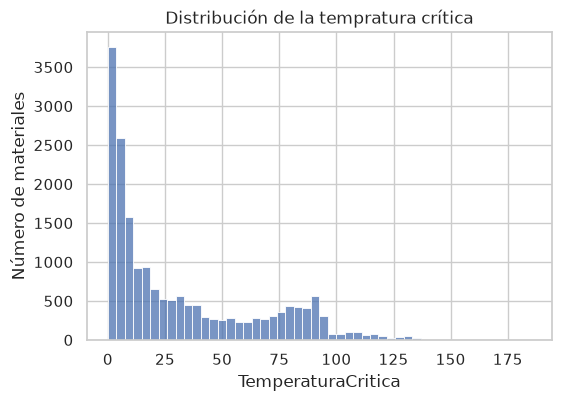

count    18533.0
mean        31.0
std         33.0
min          0.0
25%          5.0
50%         16.0
75%         54.0
max        185.0
Name: TemperaturaCritica, dtype: float64


In [10]:
plt.figure(figsize=(6, 4))
sns.histplot(data=data, x="TemperaturaCritica", bins=50)
plt.title("Distribución de la tempratura crítica")
plt.ylabel("Número de materiales")
plt.show()
print(data["TemperaturaCritica"].describe().round(0))

**Interpretación:** La distribución está fuertemente sesgada a la derecha: La mayor parte de los materiales presentan temperaturas críticas entre los 0K y los 30K, con una cola larga hacia valores más altos, con varios datos entre los 120K-130K. Esto arrastra la media (30K) muy por encima de la mediana (16K). Por lo que debemos tener cuidado con predicciones cercanas a 30K. Adicionalmente es importante resaltar otro aumento en frecuencia alrededor de 70K-90K.

### 2.3 Relación entre columnas



### ¿Se relaciona la Afinidad Electrónica media con la temperatura crítica?

Revisando el diccionario de datos, la ConductividadTermicaMedia presenta: "Conductividad térmica media (W/m·K) de los elementos que componen el material.", quiero revisar la relación de esta variable con la variable objetivo.

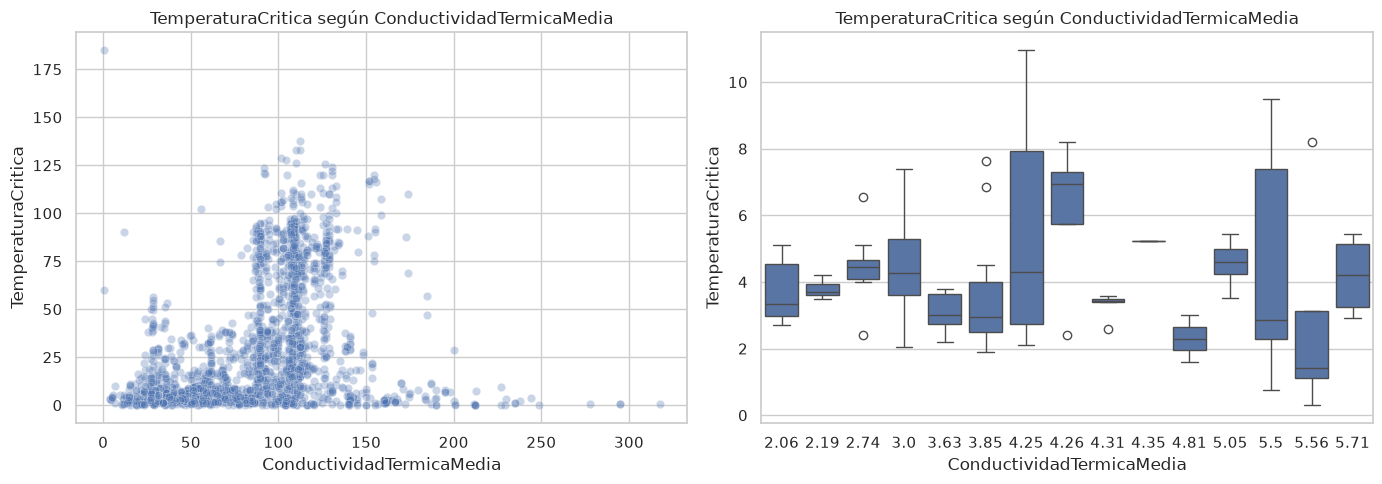

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=data.sample(2000, random_state=RANDOM_STATE),
                x="ConductividadTermicaMedia", y="TemperaturaCritica", alpha=0.3, ax=ax[0])
ax[0].set_title("TemperaturaCritica según ConductividadTermicaMedia")
sns.boxplot(data=data[data["ConductividadTermicaMedia"].between(1, 6)], x="ConductividadTermicaMedia", y="TemperaturaCritica", ax=ax[1])
ax[1].set_title("TemperaturaCritica según ConductividadTermicaMedia")
plt.tight_layout()
plt.show()

De esto puedo sospechar que la relación en general no será ni lineal ni cuadrática.

La única correlación realmente fuerte que se presenta entre la variable objetivo es con el número de elementos. Así como la correlación entre la densidadmedia y la masa atomica media, así como la valenciamedia y la densidadmedia

### Calidad de los datos

Es hora de revisar las 4 dimensiones de calidad para los datos

* **Unicidad** Es importante remover la variable ID puesto que ya sabemos por el diccionario que este dato es único.

In [12]:
# data_without_id simplemente remueve la columna ID
data_without_id = data.drop(columns="ID")
n_duplicadas = data_without_id.duplicated().sum()
print(f"Filas idénticas (duplicadas): {n_duplicadas}")

Filas idénticas (duplicadas): 300


Esta información es sumamente importante: existen **300** datos que coinciden tanto en sus propiedades fisicoquímicas como en la temperatura crítica, pese a que su ID es diferente.

**Opinion de experto de dominio:** Esta pregunta fue realizada en el foro de coursera. Resulta que esto no se trata de un error, sucede que algunas variables toman el promedio de la propiedad (promedio físico-químico, no media).

Voy a revisar qué porcentaje de los datos representan estos duplicados, y haré una comparativa de la distribución de los datos sin estos duplicados. 

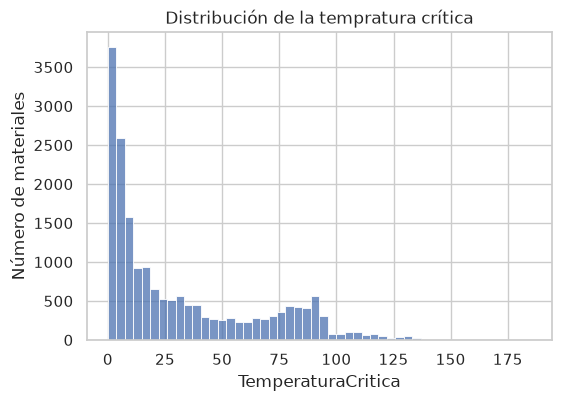

count    18233.0
mean        31.0
std         33.0
min          0.0
25%          5.0
50%         16.0
75%         54.0
max        185.0
Name: TemperaturaCritica, dtype: float64


In [13]:
#data_without_dup son los datos sin duplicados
data_without_dup = data.drop_duplicates(subset = data_without_id, keep="first")
plt.figure(figsize=(6, 4))
sns.histplot(data=data, x="TemperaturaCritica", bins=50)
plt.title("Distribución de la tempratura crítica")
plt.ylabel("Número de materiales")
plt.show()
print(data_without_dup["TemperaturaCritica"].describe().round(0))

In [14]:
data_without_dup.describe()


,ID,NumElementos,MasaAtomicaMedia,EnergiaIonizacionMedia,RadioAtomicoMedio,DensidadMedia,AfinidadElectronicaMedia,CalorFusionMedio,ConductividadTermicaMedia,ValenciaMedia,TemperaturaCritica
count,18233.000000,18233.000000,18233.000000,18233.000000,18051.000000,18051.000000,18233.000000,18233.000000,18233.000000,18051.000000,18233.000000
mean,9248.687380,4.075138,88.318373,767.883795,158.089794,6252.950543,77.046869,14.828820,87.902454,3.269090,31.399558
std,5360.844856,1.481217,30.623639,90.069952,20.668603,2926.076404,28.643143,11.579957,39.405669,1.054525,33.059413
min,1.000000,1.000000,6.940000,375.500000,48.000000,1.430000,1.500000,0.222000,0.030000,1.000000,0.000000
25%,4600.000000,3.000000,72.320000,719.270000,148.100000,4584.290000,61.400000,7.656000,58.070000,2.400000,4.610000
50%,9238.000000,4.000000,86.270000,757.900000,160.250000,5450.000000,73.000000,9.776000,93.010000,3.000000,16.400000
75%,13899.000000,5.000000,102.050000,797.150000,170.600000,7043.480000,87.100000,18.433000,110.000000,4.000000,54.000000
max,18533.000000,9.000000,208.980000,1313.100000,298.000000,22590.000000,326.100000,105.000000,332.500000,7.000000,185.000000


Decisión datos duplicados: Pese a que la diferencia es relativamente nula en ambas distribuciones, voy a conservar estos datos duplicados, la justificación de esta decisión es que estos datos al fin y al cabo representan materiales distintos, por lo que considerarlos en el modelo es fundamental para obtener una predicción más realista y hacer uso de estos datos.

- **Consistencia**

Como vimos anteriormente, todos los datos son numéricos, verifiquemos que esto realmente sea así

In [15]:
tipos = data.dtypes
no_numericas = tipos[~tipos.apply(lambda t: np.issubdtype(t, np.number))]
print("Columnas y su tipo de dato:")
print(tipos)
print("\nColumnas no numéricas encontradas:")
print(no_numericas if len(no_numericas) else "  ninguna")

Columnas y su tipo de dato:
ID                             int64
NumElementos                   int64
MasaAtomicaMedia             float64
EnergiaIonizacionMedia       float64
RadioAtomicoMedio            float64
DensidadMedia                float64
AfinidadElectronicaMedia     float64
CalorFusionMedio             float64
ConductividadTermicaMedia    float64
ValenciaMedia                float64
TemperaturaCritica           float64
dtype: object

Columnas no numéricas encontradas:
  ninguna


En este caso todas las columnas fueron marcadas como numéricas. Así que para este caso no hay ningún problema de consistencia.

- **Completitud**

In [16]:
faltantes = data.isna().sum()
print("Valores faltantes por columna (solo las que tienen):")
print(faltantes[faltantes > 0] if faltantes.sum() else "  ninguno")

Valores faltantes por columna (solo las que tienen):
RadioAtomicoMedio    188
DensidadMedia        185
ValenciaMedia        183
dtype: int64


Hay valores incompletos en las columnas: RadioAtomicoMedio, DensidadMedia y ValenciaMedia.

**Opinión de experto de dominio:** Según lo revisado en el foro de Coursera, estos datos faltantes podrían ser imputados "comparando con otros registros ya que estamos modelando con propiedades fisicoquímicas". 

Es importante mencionar que este consejo de imputar según las propiedades de los demás registros en vez de imputar mediante la media o la mediana es una consecuencia directa del sesgo que existe en la distribución de los datos. Sin embargo, ajustar los datos de la forma aconsejada puede resultar en una gran cantidad de datos con variables completadas usando ese método, dado que los datos duplicados usaron precisamente esa estrategia, por lo que a mi parecer manejar +400 datos completados usando las propiedades de otros registros puede hacer que el modelo pierda precisión.

Esto no justifica sin embargo que debamos eliminar los 300 datos duplicados, puesto que estos ya fueron imputados para este ejercicio. Adicionalmente, los datos con valores faltantes representan menos del 5% del total de los datos, por lo tanto no representan un cambio importante para el modelo, podemos sostener este argumento revisando nuevamente la distribución eliminando estos datos.

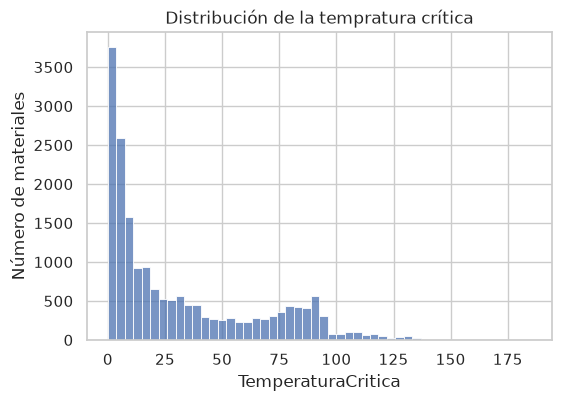

count    17981.0
mean        31.0
std         33.0
min          0.0
25%          5.0
50%         16.0
75%         54.0
max        143.0
Name: TemperaturaCritica, dtype: float64


In [17]:
# datos omitiendo registos que les falta algún valor
data_with_all_values = data.dropna()
plt.figure(figsize=(6, 4))
sns.histplot(data=data, x="TemperaturaCritica", bins=50)
plt.title("Distribución de la tempratura crítica")
plt.ylabel("Número de materiales")
plt.show()
print(data_with_all_values["TemperaturaCritica"].describe().round(0))

Aquí sucedió algo muy interesante: El dato de mayor temperatura crítica fue eliminado, y justamente buscamos materiales que sean buenos superconductores, es decir, materiales con altas temperaturas críticas (así evitamos enfriar los materiales), sin embargo, revisando el dataset original: 

In [18]:
# los 5 datos con mayor temperatura crítica
data.nlargest(5, "TemperaturaCritica")

,ID,NumElementos,MasaAtomicaMedia,EnergiaIonizacionMedia,RadioAtomicoMedio,DensidadMedia,AfinidadElectronicaMedia,CalorFusionMedio,ConductividadTermicaMedia,ValenciaMedia,TemperaturaCritica
17370,17371,2,16.54,1155.15,70.00,NaN,137.90,1.144,0.19,3.500,185.0
3772,3773,6,110.79,811.87,160.83,6482.57,53.30,6.154,110.22,2.333,143.0
6163,6164,6,110.32,790.82,161.17,6567.57,50.65,6.059,112.05,2.167,137.4
13175,13176,7,106.45,778.27,148.00,5851.20,72.40,9.319,100.29,3.143,136.0
6870,6871,5,91.51,831.20,162.20,5511.09,56.64,6.430,125.27,2.000,135.8


Vemos que el dato con ID 1731 (el máximo de la muestra origina) es un dato atípico con alta variación en su temperatura crítica (es mucho más alta incluso que las otras en la table anterior), pero con un valor faltante. No me parece razonable inputar cientos de datos solo para conservar esta instancia, puesto que la regresión podría verse sesgada ante un dato atípico que presenta ausencia de información.

Aparte de esto, vemos que el modelo no sufre de grandes cambios en sus estadísticas al eliminar estos datos. Pero mantenerlos puede representar tener muchos registros con datos imputados.

**Conclusión:** Mi decisión en este caso es eliminar los registros con valores faltantes, la justificación es el cambio relativamente nulo de las estadísticas de estos datos y el beneficio de omitir registros con muchos datos completados mediante promedios de sus cualidades fisicoquimicas. Adicionalmente, representan un porcentaje muy bajo de los datos que disponemos para el ejercicio.

-   **Validez:** Revisando nuevamente las estadísticas, vemos que existen datos con 0k como temperatura crítica, más precisamente:

In [19]:
(data["TemperaturaCritica"] == 0).sum()

np.int64(3)

Existen apenas 3 datos con esa condición

**Opinion del experto de dominio:**  El 0K en la práctica no existe

Conclusión: Sin más que agregar, es necesario eliminar estos 3 registros, la justificación es que representan temperaturas que no existen en realidad, por lo que no son datos válidos

## 3. Limpieza de los datos

Después de hacer un analisis de las 4 dimesiones de calidad en los datos, vamos a eliminar los datos con valores faltantes y los datos con temperaturas críticas iguales a 0k

In [20]:
filas_inicio = len(data)

In [21]:
data = data.dropna()

In [22]:
data = data[data["TemperaturaCritica"] != 0]

In [23]:
print(f"Filas al inicio:  {filas_inicio}")
print(f"Filas eliminadas: {filas_inicio - len(data)}")
print(f"Filas limpias:    {len(data)}")

# Verificación: los rangos ya deben ser válidos
print("\nVerificación tras limpiar:")
print(f"  Temperatura crítica -> mínimo: {data['TemperaturaCritica'].min()}, máximo: {int(data['TemperaturaCritica'].max())}")
print("  Valores con datos faltantes:", data.isna().sum().sum())

Filas al inicio:  18533
Filas eliminadas: 555
Filas limpias:    17978

Verificación tras limpiar:
  Temperatura crítica -> mínimo: 0.001, máximo: 143
  Valores con datos faltantes: 0


## 4. Preparación de los datos

### Eliminar la columna ID
Ahora, existe otra variable que cumple con las 4 dimensiones de calidad, sin embargo, no representa ninguna ventaja dentro del modelo. Esta variable es "ID". Dado que cada id es único no es una variable predictora, por lo tanto debemos omitirla

In [24]:
data = data.drop(columns=["ID"])

In [25]:
data.head()

,NumElementos,MasaAtomicaMedia,EnergiaIonizacionMedia,RadioAtomicoMedio,DensidadMedia,AfinidadElectronicaMedia,CalorFusionMedio,ConductividadTermicaMedia,ValenciaMedia,TemperaturaCritica
0,7,52.48,797.84,144.71,3053.06,67.41,27.552,117.15,2.429,117.65
1,2,123.64,652.30,174.00,6445.00,20.24,6.655,117.50,3.000,0.65
2,3,87.47,856.17,127.33,6311.00,135.13,12.233,27.51,5.000,14.80
3,4,103.91,656.92,199.75,5181.00,48.80,13.222,44.75,3.000,35.00
4,6,98.76,830.77,129.67,5913.57,89.62,23.570,104.84,3.000,55.00


In [26]:
data.shape

(17978, 10)

### Separar los datos

Dado que decidí no inputar ningún dato, para este paso hacemos **(1) separar X e y → (2) partir train/test**. Usamos la distribución 80% training - 20% test

In [27]:
# (1) Separar predictoras (X) y objetivo (y).
X = data.drop(columns="TemperaturaCritica")
y = data["TemperaturaCritica"]

# (2) Partir en train/test. random_state fija el resultado. 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)

Entrenamiento: (14382, 9)  Prueba: (3596, 9)


### Armar preparador sin inputar

En este caso usaremos StandardScaler para los modelos. Esto por facilidad

In [28]:
def construir_preparador(grado):

    # no imputamos nada
    pasos = []
    if grado > 1:
        pasos.append(("poly", PolynomialFeatures(degree=grado,
                                                 include_bias=False)))
    pasos.append(("escalar", StandardScaler()))
    return Pipeline(pasos)

Para el ejercicio usaremos polinomios de grado [2, 3]

In [29]:
for grado in [2, 3]:
    prep = construir_preparador(grado).fit(X_train, y_train)
    n = prep.transform(X_train.head(5)).shape[1]
    print(f"grado {grado}: {n:>4} columnas entran al modelo")

grado 2:   54 columnas entran al modelo
grado 3:  219 columnas entran al modelo


## 5. Modelado

### 5.1. Búsqueda del grado de la transformación polinomial con la curva de validación.

Haremos validación cruzada usando la función validation_curve

In [30]:
pipe_grado = Pipeline([
    ("poly", PolynomialFeatures(include_bias=False)),
    ("escalar", StandardScaler()),
    ("modelo", LinearRegression())
])

In [31]:
grados = [2, 3]

In [32]:
# Evalúa el efecto del grado del polinomio mediante validación cruzada.
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_scores, val_scores = validation_curve(
    pipe_grado,                 # Pipeline a evaluar.
    X_train, y_train,           # Datos de entrenamiento.
    param_name="poly__degree",  # Hiperparámetro que se va a variar.
    param_range=grados,         # Valores que tomará el grado del polinomio.
    cv=CV,                       # Validación cruzada de 5 particiones.
    scoring="neg_root_mean_squared_error"               # Métrica de evaluación (RMSE).
)

Por lo visto en el foro. Dado que scikit learn devuelve las metricas de error en negativo por ser un problema de maximización, multiplicamos el valor por -1 para obtener el valor del RMSE real.

In [33]:
train_scores *= -1
val_scores *= -1

In [34]:
# Calcula el desempeño promedio en entrenamiento y validación para cada grado.
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

In [35]:
# Muestra el RMSE promedio para cada grado del polinomio.
for g, train, val in zip(grados, train_mean, val_mean):
    print(f"Grado {g}: RMSE entrenamiento = {train:.3f} | RMSE validación = {val:.3f}")

Grado 2: RMSE entrenamiento = 19.137 | RMSE validación = 19.212
Grado 3: RMSE entrenamiento = 17.655 | RMSE validación = 18.104


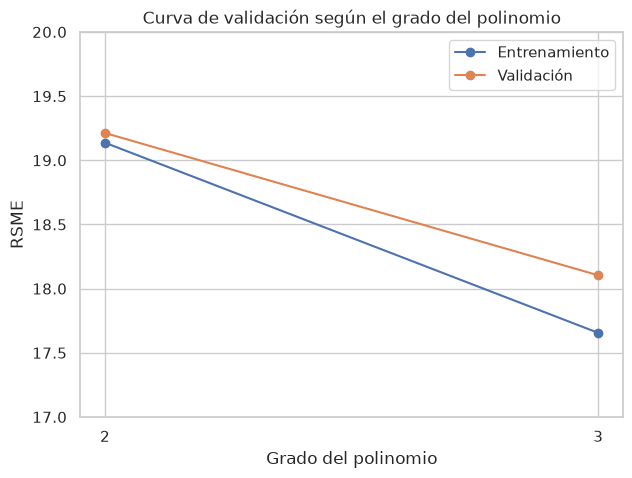

In [36]:
# Grafica la curva de validación para comparar el desempeño en entrenamiento y validación.
plt.figure(figsize=(7, 5))
plt.plot(grados, train_mean, "o-", label="Entrenamiento")
plt.plot(grados, val_mean, "o-", label="Validación")
plt.axhline(0, linestyle="--", linewidth=1)  
plt.ylim(17, 20)   # Limita el eje y según los valores de RMSE
plt.xticks(grados)
plt.xlabel("Grado del polinomio")
plt.ylabel("RSME")
plt.title("Curva de validación según el grado del polinomio")
plt.legend()
plt.show()

Vemos que el error de validación baja considerablemente al pasar de grado 2 a grado 3, también es evidente la brecha que hay entre entrenamiento y validación para ambos grados, donde la brecha en grado 2 es reducida y en grado 3 es una brecha amplia. A pesar de esto, el error de validación también disminuye, dejando pocas sospechas de un sobreajuste en grado 3

Por estas razones voy a seleccionar el grado 3

### 5.2 Regularización usando Lasso (L1)

Para este caso utilizaremos técnicas de selección de modelos para α: [1, 2, 3, 4, 5] y rmse con grado 3

#### Búsqueda de alpha para Lasso y seleccionar variables con GridSearchCV

In [37]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# tomamos alpha = [1, 2, 3, 4, 5] y el preparador de grado 3
malla_lasso = {"lasso__alpha": [1, 2, 3, 4, 5]}
busqueda_lasso = GridSearchCV(
    Pipeline([
        ("preparador", construir_preparador(3)),
        ("lasso", Lasso(max_iter=5000, tol=1e-2))]),
    malla_lasso, cv=CV, scoring="neg_root_mean_squared_error",
    return_train_score=True)

with warnings.catch_warnings(record=True) as capturados:
    warnings.simplefilter("always", category=ConvergenceWarning)
    busqueda_lasso.fit(X_train, y_train)
n_avisos = len(capturados)
if n_avisos:
    print(f"Nota: {n_avisos} de los ajustes no llegaron a la tolerancia de convergencia ")

Nuevamente multiplicamos los valores en rmse por -1

In [38]:
busqueda_lasso.cv_results_["mean_train_score"] *= -1
busqueda_lasso.cv_results_["mean_test_score"] *= -1

In [39]:
for a, train, val in zip(malla_lasso["lasso__alpha"],
                          busqueda_lasso.cv_results_["mean_train_score"],
                          busqueda_lasso.cv_results_["mean_test_score"]):
    print(f"Alpha {a:>6.2f}: RMSE entrenamiento = {train:.3f} | RMSE validación = {val:.3f}")

Alpha   1.00: RMSE entrenamiento = 20.741 | RMSE validación = 20.771
Alpha   2.00: RMSE entrenamiento = 21.347 | RMSE validación = 21.373
Alpha   3.00: RMSE entrenamiento = 22.077 | RMSE validación = 22.102
Alpha   4.00: RMSE entrenamiento = 22.539 | RMSE validación = 22.559
Alpha   5.00: RMSE entrenamiento = 23.032 | RMSE validación = 23.049


Graficamos el RMSE de validación

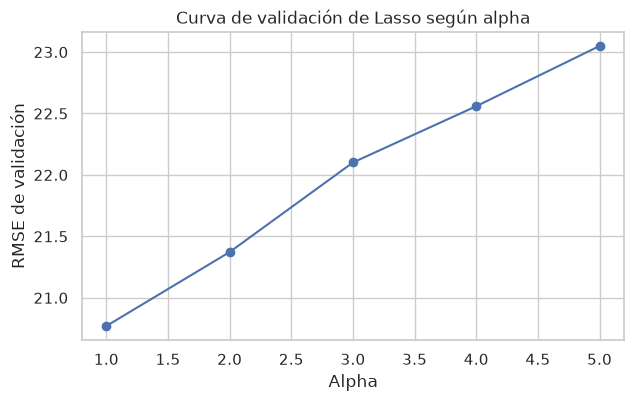

In [40]:
alphas = malla_lasso["lasso__alpha"]

rmse_val = busqueda_lasso.cv_results_["mean_test_score"]

plt.figure(figsize=(7, 4))

plt.plot(alphas, rmse_val, marker="o")

plt.xlabel("Alpha")
plt.ylabel("RMSE de validación")
plt.title("Curva de validación de Lasso según alpha")
plt.grid(True)

plt.show()

El RMSE aumenta conforme alpha crece. En ningún momento el modelo mejora el desempeño antes de deteriorarlo. Según la gráfica es claro que alpha = 1 presenta el menor error de validación. Por tanto una regularización más fuerte puede eliminar información útil para el modelo. Lasso puede ser mejor que el modelo sin regularizar en nuestro caso, dado que para la regresión de dado 3 la penalización permitirá anular múltiples variables de menor impacto en el modelo.

Revisamos el mejor alpha obtenido

In [41]:
mejor_lasso = busqueda_lasso.best_estimator_
coefs_l = mejor_lasso.named_steps["lasso"].coef_
print("Mejor alpha:", busqueda_lasso.best_params_["lasso__alpha"])
print(f"Coeficientes en cero : {(coefs_l == 0).sum()} de {len(coefs_l)}")

Mejor alpha: 1
Coeficientes en cero : 204 de 219


De esto obtenemos de nuevo que el mejor alpha es 1. Sin embargo vemos que Lasso simplificó muchísimas variables en el modelo, por lo que podemos ver que existe una penalización bastante fuerte.

Veamos cuáles variables fueron las que Lasso apagó.

In [42]:
nombres_poly = (busqueda_lasso.best_estimator_
                .named_steps["preparador"]
                .named_steps["poly"]
                .get_feature_names_out(X_train.columns))

importancia = pd.DataFrame({
    "variable": nombres_poly,
    "coeficiente": coefs_l,
}).assign(abs_coef=lambda d: d["coeficiente"].abs(),
          en_cero=lambda d: d["coeficiente"] == 0)
importancia = importancia.sort_values("abs_coef", ascending=False).reset_index(drop=True)

print("Las variables que Lasso seleccionó:")
display(importancia.head(15)[["variable", "coeficiente", "en_cero"]])

print("\nVariables que Lasso apagó (coeficiente = 0):")
display(importancia[importancia["en_cero"]][["variable", "coeficiente"]])

Las variables que Lasso seleccionó:


,variable,coeficiente,en_cero
0,NumElementos MasaAtomicaMedia ConductividadTermicaMedia,11.259250,False
1,NumElementos EnergiaIonizacionMedia ConductividadTermicaMedia,7.226345,False
2,NumElementos DensidadMedia ValenciaMedia,-4.215824,False
3,DensidadMedia ConductividadTermicaMedia^2,-2.735187,False
4,EnergiaIonizacionMedia RadioAtomicoMedio,2.729982,False
5,EnergiaIonizacionMedia^2 RadioAtomicoMedio,2.434005,False
6,NumElementos^2 ConductividadTermicaMedia,2.421054,False
7,NumElementos EnergiaIonizacionMedia RadioAtomicoMedio,2.118771,False
8,AfinidadElectronicaMedia ConductividadTermicaMedia ValenciaMedia,-1.404929,False
9,NumElementos DensidadMedia CalorFusionMedio,-1.397620,False



Variables que Lasso apagó (coeficiente = 0):


,variable,coeficiente
15,NumElementos EnergiaIonizacionMedia,0.0
16,NumElementos RadioAtomicoMedio,0.0
17,NumElementos ValenciaMedia,-0.0
18,MasaAtomicaMedia^2,-0.0
19,EnergiaIonizacionMedia,0.0
...,...,...
214,CalorFusionMedio ValenciaMedia^2,0.0
215,ConductividadTermicaMedia^3,-0.0
216,ConductividadTermicaMedia^2 ValenciaMedia,-0.0
217,ConductividadTermicaMedia ValenciaMedia^2,-0.0


Es decir, 204 términos polinomiales no aportaban casi nada.

Mensaje para el equipo de investigación: El modelo sugiere que la temperatura crítica depende especialmente de combinaciones entre el número de elementos del material, su masa atómica, conductividad térmica, energía de ionización, densidad y valencia. En particular, aparecen como relevantes las interacciones donde participa NumElementos, junto con propiedades térmicas y atómicas. Esto indica que no basta con observar una propiedad aislada, sino cómo varias características se presentan simultáneamente. En la práctica, estas combinaciones pueden servir como criterio de priorización para seleccionar qué materiales conviene sintetizar y ensayar primero en laboratorio, reduciendo el número de candidatos menos prometedores.

### Comparativa final

Con la escogencia de grado 3 y alpha = 1 hacemos una comparativa final con las métricas R², RMSE y MAE.

In [43]:
candidatos = {
    "Polinomial grado 3":   (3, LinearRegression()),
    "Grado 3 + Lasso (alpha = 1)":      (3, Lasso(alpha=1, max_iter=5000, tol=1e-2)) 
}

filas = []
for nombre, (grado, estimador) in candidatos.items():
    m = Pipeline([("preparador", construir_preparador(grado)),
                  ("modelo", estimador)]).fit(X_train, y_train)

    #añadimos estas variables para más facilidad
    
    pred_train = m.predict(X_train)
    pred_test = m.predict(X_test)

    filas.append({
        "modelo": nombre,

        "RMSE_train": round(mean_squared_error(y_train, pred_train) ** 0.5, 3),

        "RMSE_test": round(mean_squared_error(y_test, pred_test) ** 0.5, 3),

        "R2_train": round(r2_score(y_train, pred_train), 3),

        "R2_test": round(r2_score(y_test, pred_test), 3),

        "MAE_train": round(mean_absolute_error(y_train, pred_train), 3),

        "MAE_test": round(mean_absolute_error(y_test, pred_test), 3)
    })

comparativa = pd.DataFrame(filas).set_index("modelo")
comparativa

,RMSE_train,RMSE_test,R2_train,R2_test,MAE_train,MAE_test
modelo,,,,,,
Polinomial grado 3,17.680,18.333,0.713,0.696,12.441,12.850
Grado 3 + Lasso (alpha = 1),20.744,21.024,0.606,0.600,15.693,15.849


El modelo con mejor rendimiento en el conjunto de test es el polinomial de grado 3 sin regularización. Tiene un RMSE de 18.333 frente a 21.024 con Lasso, un MAE de 12.850 frente a 15.849, y además un R² de 0.696 frente a 0.600.

Esto significa que el modelo polinomial de grado 3 logra predicciones más cercanas a los valores reales y explica aproximadamente el 69.6 % de la variabilidad de la temperatura crítica en datos no vistos. El MAE indica que, en promedio, sus predicciones se desvían unos 12.85 K del valor real, mientras que el RMSE de 18.33 K muestra que algunos errores grandes tienen un peso importante. Por su parte, Lasso simplifica mucho el modelo, pero en este caso esa simplificación reduce la capacidad predictiva. Por tanto, si el objetivo principal es minimizar el error de predicción, conviene seleccionar el modelo polinomial de grado 3.

### Heatmap de correlación

Veamos el mapa de calor para analizar los datos que mejor explican mejor la temperatura.

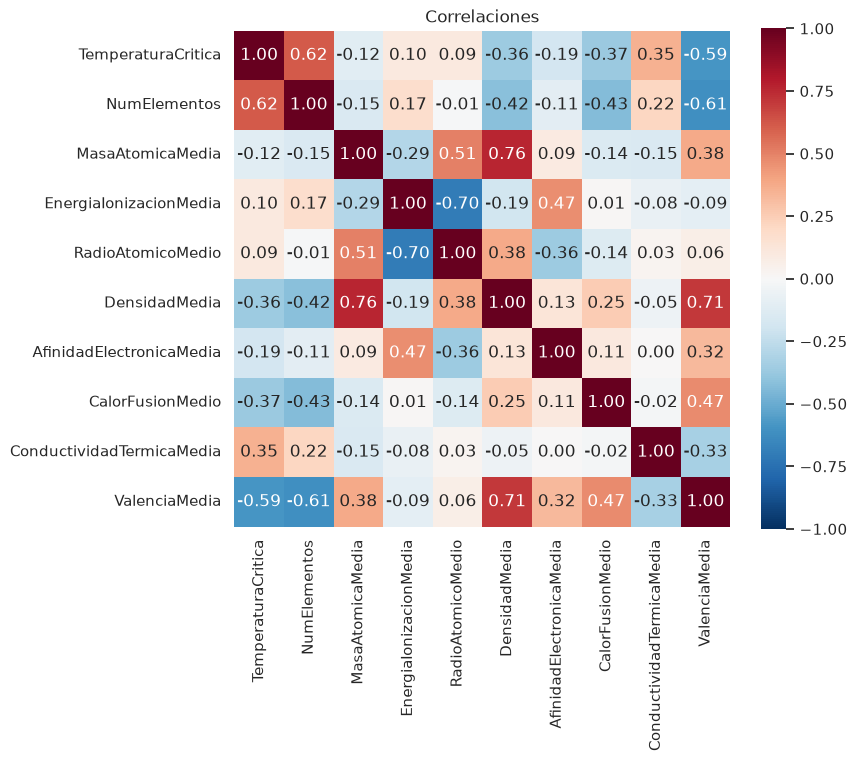

In [44]:
cols = ["TemperaturaCritica", "NumElementos", "MasaAtomicaMedia", "EnergiaIonizacionMedia", "RadioAtomicoMedio", "DensidadMedia", "AfinidadElectronicaMedia", "CalorFusionMedio", "ConductividadTermicaMedia", "ValenciaMedia"]
plt.figure(figsize=(8, 6.5))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlaciones")
plt.show()

La matriz evidencia una correlación elevada entre varios pares de propiedades, como MasaAtomicaMedia–DensidadMedia (0.76), DensidadMedia–ValenciaMedia (0.71) y EnergiaIonizacionMedia–RadioAtomicoMedio (−0.70). Cuando variables correlacionadas aportan información similar, Lasso puede conservar una de ellas y llevar otra a cero sin que esto implique que la variable descartada carezca de información sobre la temperatura crítica. Además, en el modelo polinomial una propiedad puede seguir aportando mediante interacciones aunque su término individual sea eliminado. Por ello, seleccionar variables únicamente según el error promedio puede conducir a conclusiones inestables: ante variables correlacionadas, pequeñas variaciones en los datos pueden hacer que el modelo seleccione una u otra, dificultando la interpretación física de qué propiedades son realmente relevantes.